<a href="https://colab.research.google.com/github/AngeP02/Progetto_Harrow_Hassidim_Lloyd_Quantum_Computing/blob/main/Progetto_HHL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algoritmo

## Configurazione sistema

Per la configurazione del sistema si può impostare:
* Dimensione del sistema
  * 2 indica sistema 2*2, quindi con 1 qubit di sistema
  * 4 indica sistema 4*4, quindi con 2 qubit di sistema
* Backend di simulazione
  * Simulatore che esegue si AerSimulator locale
  * Hardware IBM reale


In [ ]:
from google.colab import userdata

In [ ]:
DIMENSIONE_SISTEMA = 2
BACKEND_TIPO = "simulatore"

IBM_TOKEN = userdata.get("TOKEN_IBM")
IBM_CRN = userdata.get("CRN_IBM")

M_QUBIT_CONTROLLO = 3

NUM_SHOTS = 16384
if DIMENSIONE_SISTEMA == 2:
  n_qubit_sistema = 1
else:
  n_qubit_sistema = 2

## Dipendenze e import

In [ ]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib numpy scipy pylatexenc

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator
from qiskit.primitives import StatevectorSampler
from qiskit.circuit.library import StatePreparation
from qiskit.circuit.library import RYGate
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.converters import circuit_to_dag

## Definizione del sistema lineare e analisi spettrale

Il problema è quello di risolvere $Ax=b$ con $A$ matrice hermitiana e invertibile.

Si deve utilizzare la decomposizione spettrale
$$|x⟩ \propto A^{-1}|b⟩ = \sum_j \frac{\beta_j}{\lambda_j}|u_j⟩$$

dove $λ_j$ sono gli autovalori e $|u_j⟩$ gli autovettori di $A$.

Si definisce la matrice hermitiana del sistema sulla base della configurazione impostata

In [ ]:
if DIMENSIONE_SISTEMA == 2:
    A_originale = np.array([
        [1.5, 0.5],
        [0.5, 1.5]
    ], dtype=complex)
    b_originale = np.array([1.0, 0.0], dtype=complex)
else:
    A_originale = np.array([
        [2.0,  0.5,  0.0,  0.25],
        [0.5,  1.5,  0.25, 0.0 ],
        [0.0,  0.25, 2.0,  0.5 ],
        [0.25, 0.0,  0.5,  1.5 ]
    ], dtype=complex)
    b_originale = np.array([1.0, 0.0, 0.0, 0.0], dtype=complex)

print(f"Sistema {DIMENSIONE_SISTEMA}×{DIMENSIONE_SISTEMA}")
print(f"\nMatrice A:\n{A_originale}")
print(f"\nVettore b: {b_originale}")

Sistema 2×2

Matrice A:
[[1.5+0.j 0.5+0.j]
 [0.5+0.j 1.5+0.j]]

Vettore b: [1.+0.j 0.+0.j]


Si esegue la decomposizione spettrale di A e si calcolano:
* Autovalori $\lambda_j$ e gli autovettori $u_j$
* Coefficienti $\beta_j= \langle u_j|b\rangle$
* numero di condizionamento $k=|\lambda_{max}|/|\lambda{min}|$
* soluzione classica $x= A^{-1}b$

Viene restituito un dizionario con tutti i risultati

In [ ]:
def analisi_spettrale(A, b):
    # Normalizzazione di b
    norma_b = np.linalg.norm(b)
    b_norm = b / norma_b
    # Diagonalizzazione
    autovalori, autovettori = np.linalg.eigh(A)
    # Numero di condizionamento
    k = np.abs(autovalori[-1]) / np.abs(autovalori[0])
    # Coefficienti beta_j = <u_j | b_norm>
    beta = np.array([np.dot(autovettori[:, j].conj(), b_norm) for j in range(len(autovalori))])
    # Soluzione classica
    x_classica = np.linalg.solve(A, b_norm)
    # Soluzione ricostruita dalla decomposizione spettrale
    x_spettrale = sum((beta[j] / autovalori[j]) * autovettori[:, j] for j in range(len(autovalori)))
    return {
        "A": A,
        "b_norm": b_norm,
        "autovalori": autovalori,
        "autovettori": autovettori,
        "beta": beta,
        "k": k,
        "x_classica": x_classica,
        "x_spettrale": x_spettrale,
    }

Esecuzione analisi spettrale

In [ ]:
spettro = analisi_spettrale(A_originale, b_originale)

print(f"Matrice A:\n{spettro['A']}")
print(f"\nVettore b normalizzato: {spettro['b_norm']}")
print(f"\nAutovalori λ_j: {spettro['autovalori']}")
print(f"Autovettori (colonne):")
print(spettro['autovettori'])
print(f"\nCoefficienti β_j: {spettro['beta']}")
print(f"Numero di condizionamento κ: {spettro['k']:.4f}")
print(f"\nSoluzione classica x = A⁻¹b: {spettro['x_classica']}")
print(f"Ricostruzione spettrale: {spettro['x_spettrale']}")

Matrice A:
[[1.5+0.j 0.5+0.j]
 [0.5+0.j 1.5+0.j]]

Vettore b normalizzato: [1.+0.j 0.+0.j]

Autovalori λ_j: [1. 2.]
Autovettori (colonne):
[[-0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j  0.70710678+0.j]]

Coefficienti β_j: [-0.70710678+0.j  0.70710678+0.j]
Numero di condizionamento κ: 2.0000

Soluzione classica x = A⁻¹b: [ 0.75+0.j -0.25+0.j]
Ricostruzione spettrale: [ 0.75+0.j -0.25+0.j]


## Normalizzazione degli autovalori

L'algoritmo HHL richiede che gli autovalori siano in $[\frac{1}{k}, 1] $. Questo si ottiene dividendo la matrice $A$ per $\lambda_{max}$ così che il massimo autovalore diventi 1.

In questa funzione (**normalizza_matrice(A, autovalori)**) viene normalizzata la matrice $A$ dividendo per il modulo dell'autovalore massimo, in modo che gli autovalori normalizzati siano nel range corretto

In [ ]:
def normalizza_matrice(A, autovalori):
    lambda_max = np.max(np.abs(autovalori))
    A_norm = A / lambda_max
    return A_norm, lambda_max

In [ ]:
A_norm, lambda_max_usato = normalizza_matrice(spettro["A"], spettro["autovalori"])
autovalori_norm = spettro["autovalori"] / lambda_max_usato

k = spettro["k"]
C_costante = 1.0 / k

print(f"λ_max originale usato per normalizzare: {lambda_max_usato:.4f}")
print(f"Autovalori normalizzati: {autovalori_norm}")
print(f"Numero di condizionamento κ: {k:.4f}")
print(f"Costante C = 1/κ = {C_costante:.4f}")
print(f"Verifica C/|λ_j| ≤ 1:")
for j, lam in enumerate(autovalori_norm):
    rapporto = C_costante / np.abs(lam)
    print(f"  C/|λ_{j}| = {rapporto:.4f}")

λ_max originale usato per normalizzare: 2.0000
Autovalori normalizzati: [0.5 1. ]
Numero di condizionamento κ: 2.0000
Costante C = 1/κ = 0.5000
Verifica C/|λ_j| ≤ 1:
  C/|λ_0| = 1.0000
  C/|λ_1| = 0.5000


## Costruzione dell'operatore unitario

La QPE non può leggere direttamente una matrice generica per cui richiede come input l'operatore unitario $U= e^{iAt}$. Gli autovettori di $A$ coincidono con quelli di $U$ con autofase $\Phi_j = \lambda_j \cdotp \frac{t}{2 \pi}$

La funzione **costruisci_operatore_unitario** calcola l'operatore unitario tramite esponenziazione matriciale. Gli autovalori di $A$ diventano fasi.

In [ ]:
def costruisci_operatore_unitario(A_norm, t):
    U = expm(1j * A_norm * t)
    return U

La funzione **calcola_fasi_qpe** calcola le fasi che la QPE deve stimare, questo tenendo conto che devono essere in $[0,1)$ per evitare aliasing per questo si fa il modulo.

In [ ]:
def calcola_fasi_qpe(autovalori_norm, t):
    fasi = autovalori_norm * t / (2 * np.pi)
    fasi_mod = fasi % 1.0
    return fasi_mod

Il parametro temporale deve essere fissato in maniera tale che $\Phi_j=\lambda_j$ che per $\lambda_j \in[\frac{1}{k}, 1]$. Si calcola in modo che la fase massima sia $<1$. Pertanto $$\Phi_{max}=\lambda_{max_{normalizzato}} \cdotp \frac{t}{2\pi} <1 \rightarrow t< \frac{2\pi}{\lambda_{max_{normalizzato}}}=2\pi$$

Con $\lambda_{max_{normalizzato}} = 1$.
Per sicurezza si usa $t=2\pi \cdotp (1-\epsilon) \approx 2\pi \cdotp 0.9$

In [ ]:
t_evoluzione = 2 * np.pi * 0.9

U_matrice = costruisci_operatore_unitario(A_norm, t_evoluzione)
fasi_attese = calcola_fasi_qpe(autovalori_norm, t_evoluzione)

print(f"Parametro temporale t = {t_evoluzione:.4f} rad")
print(f"\nMatrice U = e^{{iAt}}:")
print(np.round(U_matrice, 4))
print(f"\nVerifica unitarietà U†U = I:")
identità = np.round(U_matrice.conj().T @ U_matrice, 6)
print(identità)
print(f"\nFasi attese dalla QPE φ_j = λ_j*t/(2π): {fasi_attese}")

Parametro temporale t = 5.6549 rad

Matrice U = e^{iAt}:
[[-0.071-0.1394j  0.88 -0.4484j]
 [ 0.88 -0.4484j -0.071-0.1394j]]

Verifica unitarietà U†U = I:
[[ 1.+0.j -0.-0.j]
 [-0.+0.j  1.+0.j]]

Fasi attese dalla QPE φ_j = λ_j*t/(2π): [0.45 0.9 ]


## Modulo QPE

La QPE usa $m$ qubit di controllo inizializzati a $|0\rangle$ e il registro di sistema che contiene l'autovettore $|\psi\rangle$. Si deve quindi applicare:
* Hadamard su tutti i qubit di controllo per la sovrapposizione uniforme;
* I gate controllati $C-U^{2^k}$, ovvero la fase di kickback;
* La QFT inversa per decodificare la fase in stringa binaria.

La funzione **costruisci_gate_unitario_controllato** crea il gate unitario controllato come un gate personalizzato. Riceve in input la matrice unitaria che ha dimensione $N \times N$ dell'operatore unitario e la potenza che è l'esponente $k$.

Questo gate agisce su un qubit di controllo e sugli $n$ qubit di sistema, pertanto i gate controllati operano su uno spazio di dimensione $2 \times N$.

In [ ]:
def costruisci_gate_unitario_controllato(U_matrice, potenza):
    U_potenza = np.linalg.matrix_power(U_matrice, 2**potenza)
    dim = U_potenza.shape[0]
    n_qubit_U = int(np.log2(dim))

    sottocircuito = QuantumCircuit(n_qubit_U, name=f"U^2^{potenza}")
    sottocircuito.unitary(U_potenza, list(range(n_qubit_U)))
    return sottocircuito.to_gate().control(1)

La funzione **circuito_qpe** costruisce il circuito della QPE restituendolo senza misure. Riceve in input
* Matrice dell'operatore unitario;
* Numero di qubit di controllo per la precisione della stima;
* Numero di qubit del registro di sistema.

La struttura dei registri in Qiskit è
* qubit $[0...m-1]$ per il registro di controllo;
* qubit $[m... m+n_{sys}-1]$ per il registro di sistema.

In [ ]:
def circuito_qpe(U_matrice, num_qubit_controllo, num_qubit_sistema):
    m = num_qubit_controllo
    n = num_qubit_sistema

    qc = QuantumCircuit(m + n)

    # PASSO 1: Hadamard su tutti i qubit di controllo per creare la sovrapposizione uniforme
    for qubit_ctrl in range(m):
        qc.h(qubit_ctrl)

    qc.barrier(label="Hadamard fatto")

    # PASSO 2: Applicazione dei gate controllati
    for k in range(m):
        qubit_sistema_lista = list(range(m, m + n))
        gate_controllato = costruisci_gate_unitario_controllato(U_matrice, k)
        qc.append(gate_controllato, [k] + qubit_sistema_lista)

    qc.barrier(label="Phase kickback fatto")

    # PASSO 3: QFT inversa sul registro di controllo
    iqft = QFTGate(num_qubits=m).inverse()
    qc.append(iqft, range(m))

    qc.barrier(label="IQFT fatto")

    return qc

Test dek circuito QPE

Qubit di controllo: 3  -  risoluzione 1/2^3 = 0.1250
Qubit di sistema: 1
Totale qubit QPE: 4



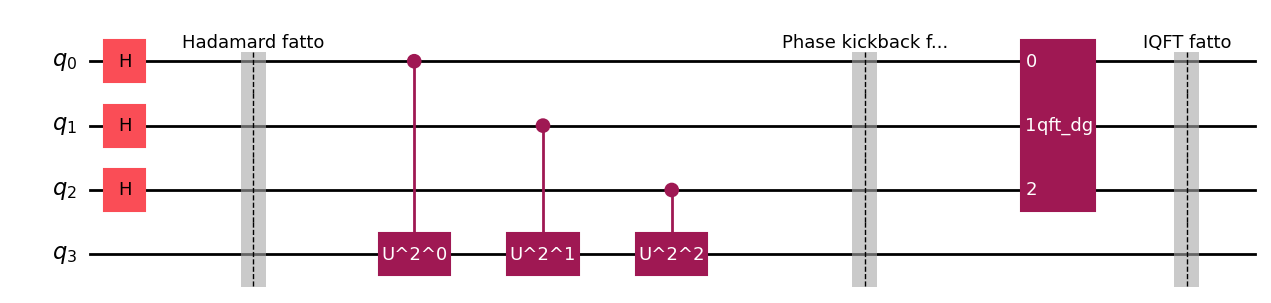

In [ ]:
m_qubit_controllo = M_QUBIT_CONTROLLO

qc_qpe_test = circuito_qpe(U_matrice, m_qubit_controllo, n_qubit_sistema)

print(f"Qubit di controllo: {m_qubit_controllo}  -  risoluzione 1/2^{m_qubit_controllo} = {1/2**m_qubit_controllo:.4f}")
print(f"Qubit di sistema: {n_qubit_sistema}")
print(f"Totale qubit QPE: {m_qubit_controllo + n_qubit_sistema}")
print()
qc_qpe_test.draw(output='mpl',fold=100)

## Rotazione condizionale con inversione degli autovalori

Il gate $R_Y(\theta_j)$ ruota il qubit ausiliario di un angolo $\theta_j=2\cdotp arsin(\frac{C}{\lambda_j})$. Questo codifica l'inversione dell'autovalore nell'ampiezza di $|1\rangle$ del qubit ausiliario, infatti:
$$|\lambda_j\rangle_C |0\rangle_a \rightarrow |\lambda_j\rangle_C (\sqrt{1- \frac{C^2}{\lambda_j^2}}|0\rangle+\frac{C}{\lambda_j}|1\rangle)$$

La funzione **calcola_angolo_rotazione** calcola l'angolo di rotazione per il gate $R_Y$. Affinchè l'arcosenno sia definito si deve avere $\frac{C}{\lambda_j}\le 1$

In [ ]:
def calcola_angolo_rotazione(C, lambda_j):
    argomento = np.clip(C / np.abs(lambda_j), -1.0, 1.0)
    angolo = 2.0 * np.arcsin(argomento)
    return angolo

La funzione **stringa_binaria_autovalore** converte un autovalore nella sua rappresentazione binaria come stima della QPE con $m$ qubit di controllo

In [ ]:
def stringa_binaria_autovalore(autovalore_norm, t, num_qubit_controllo):
    m = num_qubit_controllo
    fase = autovalore_norm * t / (2 * np.pi)
    fase = fase % 1.0
    y = int(round(fase * (2**m))) % (2**m)
    stringa = format(y, f"0{m}b")
    return y, stringa

La funzione **circuito_rotazione_condizionale** costruisce il sottocircuito della rotazione condizionale. Per ogni autovalore $\lambda_j$ calcola:
* la sua stringa binaria $y_j$ nel registro di controllo;
* l'angolo $\theta_j = 2 \cdotp arcsin(\frac{C}{\lambda_j})$;
* applica $R_Y(\theta_j)$ sul qubit ausiliario condizionata allo stato $|y_j\rangle_C$.

Ogni qubit di controllo è attivato in positivo o negato tramite il gate X prima e dopo il gate controllato.

In [ ]:
def circuito_rotazione_condizionale(autovalori_norm, C_costante, t_evoluzione, num_qubit_controllo, qubit_controllo_lista, qubit_ausiliario):
    m = num_qubit_controllo
    num_qubit_tot = m + n_qubit_sistema + 1

    qc = QuantumCircuit(num_qubit_tot)
    for j, lam in enumerate(autovalori_norm):
        y_j, stringa_j = stringa_binaria_autovalore(lam, t_evoluzione, m)
        fase_stimata = y_j / (2**m)
        if fase_stimata == 0:
            continue

        lam_tilde = fase_stimata * (2 * np.pi) / t_evoluzione
        angolo_j = calcola_angolo_rotazione(C_costante, lam_tilde)
        qubit_da_flippare = [qubit_controllo_lista[k] for k in range(m) if stringa_j[m - 1 - k] == '0']
        for q in qubit_da_flippare:
            qc.x(q)

        ry_ctrl = RYGate(angolo_j).control(len(qubit_controllo_lista))
        qc.append(ry_ctrl, qubit_controllo_lista + [qubit_ausiliario])
        for q in qubit_da_flippare:
            qc.x(q)

    return qc

Verifica degli angoli

In [ ]:
print(f"Costante C = 1/κ = {C_costante:.4f}\n")
for j, lam in enumerate(autovalori_norm):
    y_j, stringa_j = stringa_binaria_autovalore(lam, t_evoluzione, m_qubit_controllo)

    fase_stimata = y_j / (2**m_qubit_controllo)
    lam_tilde = fase_stimata * (2 * np.pi) / t_evoluzione

    angolo = calcola_angolo_rotazione(C_costante, lam_tilde)
    print(f"λ_reale = {lam:.4f} → pattern QPE = |{stringa_j}⟩ → λ_stimato = {lam_tilde:.4f}")
    print(f"  θ_rot = {angolo:.4f} rad, C/λ_stimato = {C_costante/lam_tilde:.4f}\n")

Costante C = 1/κ = 0.5000

λ_reale = 0.5000 → pattern QPE = |100⟩ → λ_stimato = 0.5556
  θ_rot = 2.2395 rad, C/λ_stimato = 0.9000

λ_reale = 1.0000 → pattern QPE = |111⟩ → λ_stimato = 0.9722
  θ_rot = 1.0803 rad, C/λ_stimato = 0.5143



## Circuito HHL completo

La struttura del circuito completo presenta:
|Nome          |Valore |
|--------------|--------------|
|Registro di sistema  |$|0\rangle \rightarrow preparazione |b\rangle$           |
|Registro di controllo|$|0\rangle ^{\otimes m}\rightarrow QPE \rightarrow rotazione condizionale \rightarrow QPE^{-1} $|
|Qubit ausiliario |$|0\rangle \rightarrow rotazione condizionale \rightarrow misura$|

In questo modo si realizza
$$|0\rangle_C|b\rangle_S|0\rangle_a \xrightarrow{\text{QPE}} \sum_j\beta_j|\lambda_j\rangle_C|u_j\rangle_S|0\rangle_a \xrightarrow{R_Y} \xrightarrow{\text{QPE}^{-1}} \sum_j\beta_j|u_j\rangle_S\left(\cdots|0\rangle_a + \frac{C}{\lambda_j}|1⟩_a\right)|0\rangle_C$$

La funzione **prepara_stato_b** prepara lo stato quantistico $|b\rangle$ nel registro di sistema. Per un vettore 2D normalizzato usa una singola rotazione $R_Y$ mentre in generale si utilizza una Quantum State Preparation arbitraria. In questa implementazione si assuma $|b\rangle$ reale. Per
* $n=1$ qubit, quindi sistema $2 \times 2$, si ha una singola rotazione $R_Y$;
* $n=2$ qubi, quindi sistema $4 \times 4$ si ha StatePreparation in Qiskit

In [ ]:
def prepara_stato_b(b_norm, n_qubit_sis, idx_sistema_lista, qc):
    b_reale = np.real(b_norm)
    b_reale = b_reale / np.linalg.norm(b_reale)

    if n_qubit_sis == 1:
        angolo_ry = 2.0 * np.arctan2(b_reale[1], b_reale[0])
        qc.ry(angolo_ry, idx_sistema_lista[0])
    else:
        gate_prep = StatePreparation(b_reale.tolist())
        qc.append(gate_prep, idx_sistema_lista)

La funzione **costruisci_circuito_hhl** costruisce il circuito quantistico completo. In particolare:
* prepara lo stato $|b\rangle$;
* QPE sul registro di controllo e di sistema;
* Rotazione condizionale sul qubit ausiliario;
* QPE inversa;
* Misura del qubit ausiliario e del sistema.

In [ ]:
def costruisci_circuito_hhl(A_norm, b_norm, autovalori_norm, C_costante, t_evoluzione, m_qubit_controllo, n_qubit_sis):

    m = m_qubit_controllo
    idx_sistema_lista = list(range(m, m + n_qubit_sis))
    idx_ausiliario = m + n_qubit_sis
    num_qubit_tot = m + n_qubit_sis + 1

    reg_q = QuantumRegister(num_qubit_tot, name='q')
    reg_c = ClassicalRegister(1 + n_qubit_sis, name='c')
    qc = QuantumCircuit(reg_q, reg_c)

    # FASE 1: Preparazione dello stato |b⟩
    qc.barrier(label="FASE 1")
    prepara_stato_b(b_norm, n_qubit_sis, idx_sistema_lista, qc)

    # FASE 2: QPE con estrazione autovalori
    qc.barrier(label="FASE 2")
    qpe_sub = QuantumCircuit(m + n_qubit_sis, name="QPE")
    qubit_sis_in_qpe = list(range(m, m + n_qubit_sis))
    for ki in range(m):
        qpe_sub.h(ki)
    for ki in range(m):
        gate_ctrl = costruisci_gate_unitario_controllato(costruisci_operatore_unitario(A_norm, t_evoluzione), ki)
        qpe_sub.append(gate_ctrl, [ki] + qubit_sis_in_qpe)
    iqft_gate = QFTGate(num_qubits=m).inverse()
    qpe_sub.append(iqft_gate, list(range(m)))
    qc.append(qpe_sub, list(range(m)) + idx_sistema_lista)

    # FASE 3: Rotazione condizionale
    qc.barrier(label="FASE 3")
    for j, lam in enumerate(autovalori_norm):
        y_j, stringa_j = stringa_binaria_autovalore(lam, t_evoluzione, m)
        fase_stimata = y_j / (2**m)
        if fase_stimata == 0:
            continue
        lam_tilde = fase_stimata * (2 * np.pi) / t_evoluzione
        angolo_j = calcola_angolo_rotazione(C_costante, lam_tilde)
        qubit_da_flippare = [ki for ki in range(m) if stringa_j[m - 1 - ki] == '0']
        for q in qubit_da_flippare:
            qc.x(q)
        ry_ctrl = RYGate(angolo_j).control(m)
        qc.append(ry_ctrl, list(range(m)) + [idx_ausiliario])
        for q in qubit_da_flippare:
            qc.x(q)

    # FASE 4: QPE inversa
    qc.barrier(label="FASE 4")
    qc.append(qpe_sub.inverse(), list(range(m)) + idx_sistema_lista)

    # FASE 5: Misura
    qc.barrier(label="FASE 5: misura")
    qc.measure(idx_ausiliario, 0)
    for qi, idx_s in enumerate(idx_sistema_lista):
        qc.measure(idx_s, 1 + qi)

    return qc

Costruzione del circuito HHL completo

Totale qubit: 5
  - Registro di controllo C: 3 qubit
  - Registro di sistema S: 1 qubit
  - Qubit ausiliario a: 1 qubit
Profondità del circuito: 8



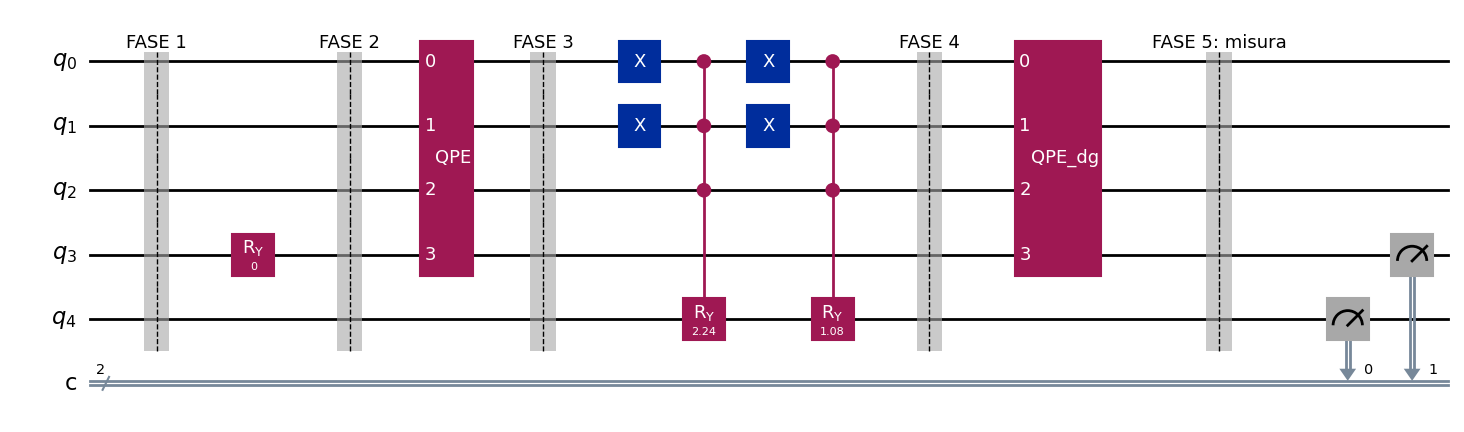

In [ ]:
U_mat = costruisci_operatore_unitario(A_norm, t_evoluzione)
circuito_hhl = costruisci_circuito_hhl(
    A_norm = A_norm,
    b_norm = spettro["b_norm"],
    autovalori_norm = autovalori_norm,
    C_costante = C_costante,
    t_evoluzione = t_evoluzione,
    m_qubit_controllo = m_qubit_controllo,
    n_qubit_sis = n_qubit_sistema
)

print(f"Totale qubit: {circuito_hhl.num_qubits}")
print(f"  - Registro di controllo C: {m_qubit_controllo} qubit")
print(f"  - Registro di sistema S: {n_qubit_sistema} qubit")
print(f"  - Qubit ausiliario a: 1 qubit")
print(f"Profondità del circuito: {circuito_hhl.depth()}")
print()
circuito_hhl.decompose(gates_to_decompose=['QPE_inv_dg']).draw(output='mpl', fold=120)

## Simulazione e post selezione

Si esegue la simulazione e si applica la post selezione, ovvero:
* se il qubit ausiliario misura 1 allora la soluzione si mette nel registro di sistema
* se il qubit ausiliario misura 0 allora si ripete o si applica l'amplitude amplification.

La probabilità di successo è $P_1 \ge \frac{1}{k^2}$

Sulla base del backend configurato si sceglie se usare AerSimulator o hardware IBM

La funzione **post_selezione** seleziona solo le misure in cui il qubit ausiliario è 1. Restituisce il dizionario con i soli esiti di successo, la probabilità di successo e le probabilità di successo e sistema condizionate al successo.

In [ ]:
def post_selezione(conteggi, num_shots):
    conteggi_successo = {}
    totale_successo = 0

    for chiave, contatore in conteggi.items():
        chiave_pulita = chiave.replace(" ", "")
        bit_ausiliario = chiave_pulita[-1]
        bit_sistema    = chiave_pulita[:-1]  # tutti i bit tranne l'ausiliario
        if bit_ausiliario == '1':
            conteggi_successo[bit_sistema] = conteggi_successo.get(bit_sistema, 0) + contatore
            totale_successo += contatore

    probabilità_successo = totale_successo / num_shots
    prob_sistema = {k: v / totale_successo for k, v in conteggi_successo.items()}
    return conteggi_successo, probabilità_successo, prob_sistema

La funzione **invia_job_reale** invia il job e restituisce l'oggetto job, non aspetta il risultato.

In [ ]:
def invia_job_reale(circuito, num_shots=8192):
    service = QiskitRuntimeService(
        channel="ibm_cloud",
        token=IBM_TOKEN,
        instance=IBM_CRN
    )
    backend = service.least_busy(
        operational=True,
        simulator=False,
        min_num_qubits=circuito.num_qubits
    )
    print(f"Backend selezionato: {backend.name}")
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
    circuito_compilato = pm.run(circuito)
    sampler = SamplerV2(mode=backend)
    job = sampler.run([circuito_compilato], shots=num_shots)
    print(f"Job inviato: {job.job_id()}")
    print(f" ID: {job.job_id()}")
    return job

La funzione **recupera_conteggi** recupera i risultati da un job già completato tramite ID

In [ ]:
import time

In [ ]:
def recupera_conteggi(job_id, num_shots=8192):
    service = QiskitRuntimeService(
        channel="ibm_cloud",
        token=IBM_TOKEN,
        instance=IBM_CRN
    )
    job = service.job(job_id)
    print(f"Stato job: {job.status()}")
    # The job.status() method returns a string directly for older Qiskit versions or specific job types.
    # We should directly compare the string returned by job.status() with the list of desired states.
    while job.status() not in ["DONE", "ERROR", "CANCELLED"]:
        print(f"In attesa... stato: {job.status()}")
        time.sleep(30)
    if job.status() == "ERROR":
        raise RuntimeError("Il job è terminato con errore")
    pub_result = job.result()[0]
    bit_array = pub_result.data.c
    bitstrings = bit_array.get_bitstrings()
    conteggi = {}
    for campione in bitstrings:
        conteggi[campione] = conteggi.get(campione, 0) + 1
    return conteggi

In [ ]:
def esegui_simulazione(circuito, num_shots=8192):
    if BACKEND_TIPO == "simulatore":
        simulatore = AerSimulator()
        circuito_compilato = transpile(circuito, simulatore)
        risultato = simulatore.run(circuito_compilato, shots=num_shots).result()
        return risultato.get_counts()
    else:
        job = invia_job_reale(circuito, num_shots)
        return job.job_id()

In [ ]:
JOB_ID = "d94ncinu62ks73968a50"

In [ ]:
if BACKEND_TIPO == "simulatore":
    conteggi_totali = esegui_simulazione(circuito_hhl, num_shots=NUM_SHOTS)
else:
    if JOB_ID == "":
        job = invia_job_reale(circuito_hhl, num_shots=NUM_SHOTS)
        JOB_ID = job.job_id()
        print(f"JOB_ID: {JOB_ID}")
        #conteggi_totali = recupera_conteggi(JOB_ID, NUM_SHOTS)
    else:
        conteggi_totali = recupera_conteggi(JOB_ID, NUM_SHOTS)
conteggi_ok, prob_successo, distribuzione_sistema = post_selezione(conteggi_totali, NUM_SHOTS)

print(f"Conteggi totali (tutti gli esiti):")
for chiave, val in sorted(conteggi_totali.items()):
    chiave_pulita = chiave.replace(" ","")
    bit_aus = chiave_pulita[-1]
    bit_sis = chiave_pulita[:-1]
    print(f"  |sistema={bit_sis}, ausiliario={bit_aus}⟩ : {val:5d}  ({100*val/NUM_SHOTS:.1f}%)")

print(f"\nPost-selezione (ausiliario = 1):")
print(f"  Probabilità di successo P₁ = {prob_successo:.4f}")
print(f"  Limite teorico 1/κ² = {1/k**2:.4f}")
print(f"  Verifica P₁ ≥ 1/κ²: {'Ok' if prob_successo >= 1/k**2 else 'No'}")
print(f"\nDistribuzione del sistema dato successo:")
for stato, prob in sorted(distribuzione_sistema.items()):
    print(f"  P(|{stato}⟩_S | ausiliario=1) = {prob:.4f}")

qiskit_runtime_service._discover_account:WARNING:2026-07-05 07:26:14,232: Loading account with the given token. A saved account will not be used.


Stato job: DONE
Conteggi totali (tutti gli esiti):
  |sistema=0, ausiliario=0⟩ :  8207  (50.1%)
  |sistema=0, ausiliario=1⟩ :  4007  (24.5%)
  |sistema=1, ausiliario=0⟩ :  2441  (14.9%)
  |sistema=1, ausiliario=1⟩ :  1729  (10.6%)

Post-selezione (ausiliario = 1):
  Probabilità di successo P₁ = 0.3501
  Limite teorico 1/κ² = 0.2500
  Verifica P₁ ≥ 1/κ²: Ok

Distribuzione del sistema dato successo:
  P(|0⟩_S | ausiliario=1) = 0.6986
  P(|1⟩_S | ausiliario=1) = 0.3014


## Estrazione della soluzione e confronto classico

La funzione **estrai_soluzione_quantistica** dalla distribuzione di probabilità del sistema estrae le componenti della soluzione normalizzata. Poichè dalla misura si ottiene $|x_j|^2$ si recupera $|x_j|=\sqrt{prob_j}$. La soluzione quantistica ha norma 1 per costruzione

In [ ]:
def estrai_soluzione_quantistica(distribuzione_sistema, n_qubit_sis):
    n_stati = 2 ** n_qubit_sis
    ampiezze = []
    for i in range(n_stati):
        stringa_stato = format(i, f"0{n_qubit_sis}b")
        prob = distribuzione_sistema.get(stringa_stato, 0.0)
        ampiezze.append(np.sqrt(prob))
    soluzione_quantistica_norm = np.array(ampiezze)
    return soluzione_quantistica_norm

La funzione **confronto_classico_quantistico** confronta la soluzione classica con quella quantistica considerando che la soluzione quantistica è normalizzata. Poichè la misura quantistica distrugge l'informazione sulla fase, sul segno, il calcolo della fedeltà e il confronto vengono effettuati sui moduli delle ampiezze come $$F=| \langle x_{classico_{normalizzato}} | x_{quantistico_{normalizzato}}\rangle|^2$$

In [ ]:
def confronto_classico_quantistico(x_classica, x_quantistica_norm, b_norm):
    norma_x_class = np.linalg.norm(x_classica)
    x_class_norm = x_classica / norma_x_class
    x_class_abs = np.abs(x_class_norm)
    x_class_abs = x_class_abs / np.linalg.norm(x_class_abs)
    fedeltà = np.abs(np.dot(x_class_abs.conj(), x_quantistica_norm))**2
    angolo_classico = np.arctan2(float(np.abs(np.real(x_class_norm[1]))), float(np.abs(np.real(x_class_norm[0]))))
    angolo_quantistico = np.arctan2(float(x_quantistica_norm[1]), float(x_quantistica_norm[0]))
    return {
        "x_class_norm": x_class_norm,
        "x_class_abs": x_class_abs,
        "x_quant_norm": x_quantistica_norm,
        "norma_classica": norma_x_class,
        "fedeltà": fedeltà,
        "angolo_classico": angolo_classico,
        "angolo_quantistico": angolo_quantistico,
    }

Estrazione e confronto dei risultati

In [ ]:
x_quant_norm = estrai_soluzione_quantistica(distribuzione_sistema, n_qubit_sistema)
risultati = confronto_classico_quantistico(spettro["x_classica"], x_quant_norm, spettro["b_norm"])

print(f"\nSoluzione classica x = A⁻¹b: {spettro['x_classica']}")
print(f" (normalizzata): {risultati['x_class_norm']}")
print(f" (norma): {risultati['norma_classica']:.4f}")
print(f"\nSoluzione quantistica |x_norm⟩: {risultati['x_quant_norm']}")
print(f" (norma = 1 per costruzione)")
print(f"\nFedeltà F = |⟨x_class|x_quant⟩|²: {risultati['fedeltà']:.6f}")
print(f"  (F=1 → soluzioni parallele, risultato ideale)")
print(f"\nAngolo classico: {np.degrees(risultati['angolo_classico']):.2f}°")
print(f"Angolo quantistico: {np.degrees(risultati['angolo_quantistico']):.2f}°")
print(f"Errore angolare: {np.abs(np.degrees(risultati['angolo_classico'] - risultati['angolo_quantistico'])):.2f}°")


Soluzione classica x = A⁻¹b: [ 0.75+0.j -0.25+0.j]
 (normalizzata): [ 0.9486833 +0.j -0.31622777+0.j]
 (norma): 0.7906

Soluzione quantistica |x_norm⟩: [0.83580526 0.54902602]
 (norma = 1 per costruzione)

Fedeltà F = |⟨x_class|x_quant⟩|²: 0.934184
  (F=1 → soluzioni parallele, risultato ideale)

Angolo classico: 18.43°
Angolo quantistico: 33.30°
Errore angolare: 14.87°


# Valutazione algoritmo

## Accuratezza della QPE

La QPE stima la fase $\varphi_j = \lambda_j \cdot \frac{t}{2\pi}$ di ogni autovalore usando $m$ qubit di controllo. La risoluzione della stima è $\frac{1}{2^m}$ e l'errore massimo garantito è

$$|\hat{\varphi} - \varphi| \leq \frac{1}{2^{m+1}}$$

All'aumentare di $m$ l'errore decresce esponenzialmente. Si analizza questo comportamento al variare di $m$ da 2 a 8 qubit

In [ ]:
def analisi_precisione_qpe(autovalori_norm, t_evoluzione, lista_m):
    risultati_precisione = []
    for m in lista_m:
        errori = []
        for lam in autovalori_norm:
            fase_vera = lam * t_evoluzione / (2 * np.pi) % 1.0
            y_j = int(round(fase_vera * 2**m)) % 2**m
            fase_stimata = y_j / 2**m
            errore = abs(fase_vera - fase_stimata)
            errori.append(errore)
        errore_max = max(errori)
        limite_teorico = 1.0 / 2**(m + 1)
        risultati_precisione.append({
            "m" : m,
            "errori" : errori,
            "errore_max" : errore_max,
            "limite_teorico": limite_teorico,
            "risoluzione" : 1.0 / 2**m,
        })
    return risultati_precisione

In [ ]:
lista_m_analisi = list(range(2, 9))
precisione = analisi_precisione_qpe(autovalori_norm, t_evoluzione, lista_m_analisi)

print(f"{'m':>4} | {'Risoluzione':>12} | {'Errore max':>12} | {'Limite 1/2^(m+1)':>18} | {'Verifica':>14}")
print("-" * 72)
for r in precisione:
    ok = 'Verificato' if r['errore_max'] <= r['limite_teorico'] + 1e-10 else 'Non verificato'
    print(f"{r['m']:>4} | {r['risoluzione']:>12.6f} | {r['errore_max']:>12.6f} | "
          f"{r['limite_teorico']:>18.6f} | {ok:>14}")


   m |  Risoluzione |   Errore max |   Limite 1/2^(m+1) |       Verifica
------------------------------------------------------------------------
   2 |     0.250000 |     0.900000 |           0.125000 | Non verificato
   3 |     0.125000 |     0.050000 |           0.062500 |     Verificato
   4 |     0.062500 |     0.025000 |           0.031250 |     Verificato
   5 |     0.031250 |     0.012500 |           0.015625 |     Verificato
   6 |     0.015625 |     0.006250 |           0.007812 |     Verificato
   7 |     0.007812 |     0.003125 |           0.003906 |     Verificato
   8 |     0.003906 |     0.001563 |           0.001953 |     Verificato


## Fidelity della soluzione quantistica

La fedeltà misura quanto la soluzione quantistica $|x_Q\rangle$ si avvicina alla soluzione classica normalizzata $|x_C\rangle$:

$$F = |\langle x_C | x_Q \rangle|^2$$

Poiché la misura quantistica distrugge l'informazione di fase e segno, il confronto viene effettuato sui moduli delle ampiezze. Una fedeltà $F = 1$ indica accordo perfetto.

In [ ]:
print(f"Soluzione classica (norm.) = {risultati['x_class_norm']}")
print(f"Soluzione quantistica = {risultati['x_quant_norm']}")
print(f"Fedeltà F = {risultati['fedeltà']:.6f}")

Soluzione classica (norm.) = [ 0.9486833 +0.j -0.31622777+0.j]
Soluzione quantistica = [0.83580526 0.54902602]
Fedeltà F = 0.934184


## Effetto di condizionamento

Il numero di condizionamento $\kappa = \lambda_{max}/\lambda_{min}$ influenza direttamente la probabilità di successo dell'algoritmo HHL. In particolare si dimostra che

$$P_1 \geq \frac{1}{\kappa^2}$$

All'aumentare di $\kappa$ la probabilità di successo diminuisce e la fedeltà può degradare a causa dell'errore di approssimazione della QPE sugli autovalori più piccoli. Si testano tre matrici con $\kappa$ crescente mantenendo la stessa struttura della matrice principale.

In [ ]:
print(f"κ = {k:.4f}")
print(f"P₁ simulata = {prob_successo:.4f}")
print(f"Limite teorico 1/κ² = {1/k**2:.4f}")
print(f"Verifica P₁ ≥ 1/κ² = {'Ok' if prob_successo >= 1/k**2 else 'No'}")

κ = 2.0000
P₁ simulata = 0.3501
Limite teorico 1/κ² = 0.2500
Verifica P₁ ≥ 1/κ² = Ok


## Analisi del gate count

La complessità circuitale dell'algoritmo HHL scala come $O(s^2 \kappa \log(N) / \varepsilon)$ dove:
* $N$ è la dimensione del sistema lineare
* $\kappa$ è il numero di condizionamento
* $s$ è la sparsità della matrice
* $\varepsilon$ è la precisione desiderata

Il numero di qubit totali è $m + \log_2(N) + 1$ dove $m$ è il numero di qubit di controllo per la QPE. Si confronta il gate count tra sistema $2\times2$ e $4\times4$.

In [ ]:
dag = circuit_to_dag(circuito_hhl.decompose(reps=5))
ops = dag.count_ops()
gate_1q = sum(v for k, v in ops.items() if k not in ['cx','ccx','cu','mcx','measure','barrier'])
gate_2q = sum(v for k, v in ops.items() if k in ['cx','cu'])

print(f"Qubit totali = {circuito_hhl.num_qubits}  ({m_qubit_controllo}C + {n_qubit_sistema}S + 1A)")
print(f"Profondità = {circuito_hhl.depth()}")
print(f"Gate totali = {sum(ops.values())}")
print(f"Gate 1-qubit = {gate_1q}")
print(f"Gate 2-qubit = {gate_2q}")

Qubit totali = 5  (3C + 1S + 1A)
Profondità = 8
Gate totali = 218
Gate 1-qubit = 141
Gate 2-qubit = 70
